In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
columns = [
    "area",
    "perimeter",
    "compactness",
    "kernel_length",
    "kernel_width",
    "asymmetry_coefficient",
    "kernel_groove_length",
    "variety"
]

seeds = pd.read_csv("seeds.csv", header=None, names=columns)

print("Dataset loaded successfully!")
print("Dataset shape:", seeds.shape)

seeds.head()

Dataset loaded successfully!
Dataset shape: (210, 8)


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coefficient,kernel_groove_length,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [4]:
print("Dataset information:")
seeds.info()

print("\nStatistical summary:")
display(seeds.describe())

print("\nMissing values:")
print(seeds.isnull().sum())

print("\nDuplicate rows:", seeds.duplicated().sum())

print("\nSeed varieties:")
print(seeds["variety"].value_counts().sort_index())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   area                   210 non-null    float64
 1   perimeter              210 non-null    float64
 2   compactness            210 non-null    float64
 3   kernel_length          210 non-null    float64
 4   kernel_width           210 non-null    float64
 5   asymmetry_coefficient  210 non-null    float64
 6   kernel_groove_length   210 non-null    float64
 7   variety                210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.2 KB

Statistical summary:


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coefficient,kernel_groove_length,variety
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000



Missing values:
area                     0
perimeter                0
compactness              0
kernel_length            0
kernel_width             0
asymmetry_coefficient    0
kernel_groove_length     0
variety                  0
dtype: int64

Duplicate rows: 0

Seed varieties:
variety
1    70
2    70
3    70
Name: count, dtype: int64


In [5]:
# Remove duplicate rows if any
seeds = seeds.drop_duplicates().copy()

# Check missing values
print("Missing values before handling:")
print(seeds.isnull().sum())

# Remove rows with missing values, if any
seeds = seeds.dropna()

print("\nDataset shape after cleaning:", seeds.shape)
print("Data cleaning completed!")

Missing values before handling:
area                     0
perimeter                0
compactness              0
kernel_length            0
kernel_width             0
asymmetry_coefficient    0
kernel_groove_length     0
variety                  0
dtype: int64

Dataset shape after cleaning: (210, 8)
Data cleaning completed!


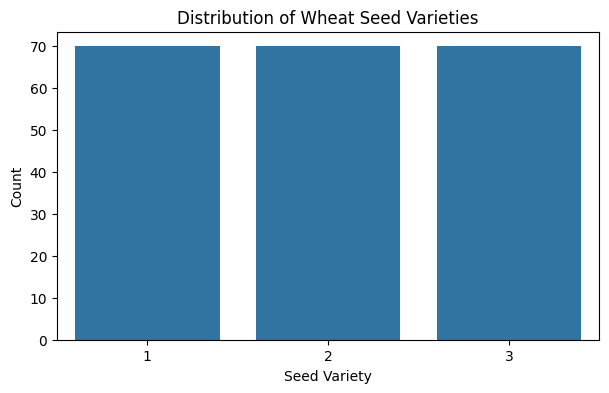

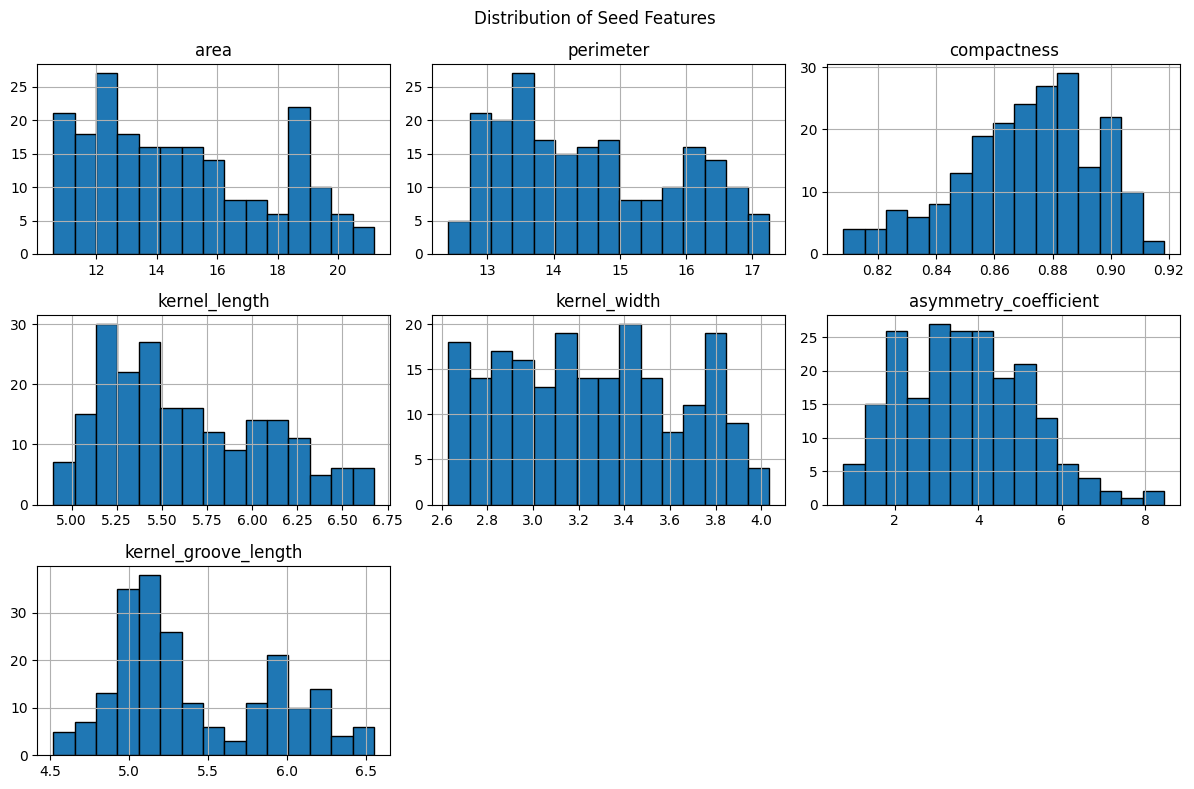

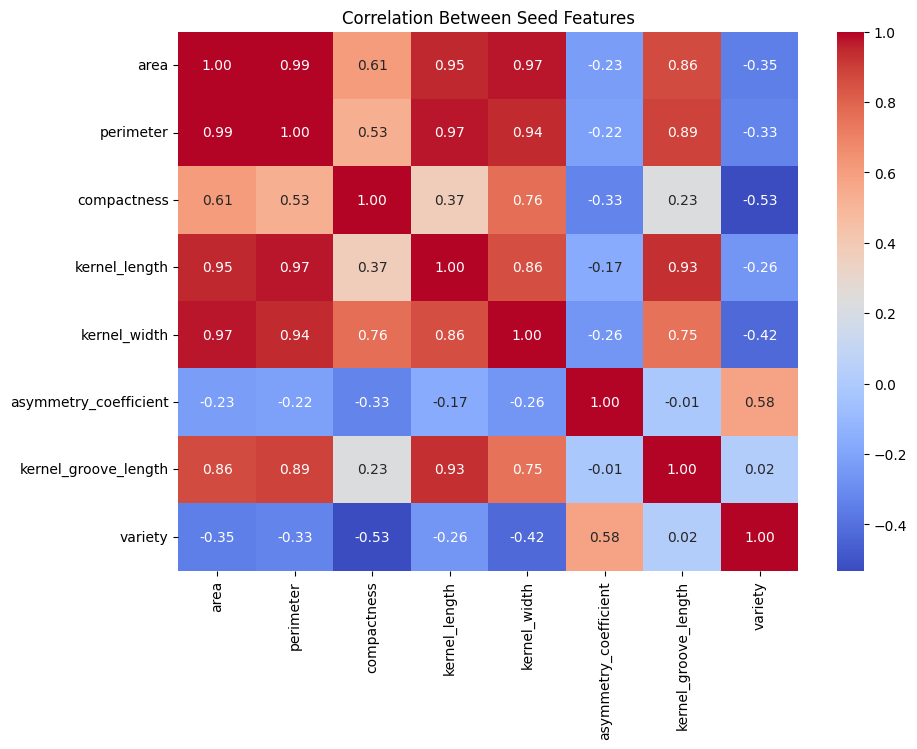

All visualizations completed successfully!


In [6]:

# Step 5: Data Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Distribution of wheat seed varieties
plt.figure(figsize=(7, 4))
sns.countplot(data=seeds, x="variety")
plt.title("Distribution of Wheat Seed Varieties")
plt.xlabel("Seed Variety")
plt.ylabel("Count")
plt.show()

# 2. Distribution of seed features
seeds.drop(columns="variety").hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)
plt.suptitle("Distribution of Seed Features")
plt.tight_layout()
plt.show()

# 3. Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    seeds.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Seed Features")
plt.show()

print("All visualizations completed successfully!")


In [7]:
X = seeds.drop(columns=["variety"])
y = seeds["variety"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (210, 7)
Target shape: (210,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 168
Testing samples: 42


In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [10]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = {}

for name, model in models.items():

    if name == "KNN":
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    results[name] = accuracy

    print(f"{name} Accuracy: {accuracy:.2%}")

KNN Accuracy: 90.48%
Decision Tree Accuracy: 88.10%
Random Forest Accuracy: 90.48%


,Model,Accuracy
0,KNN,0.904762
2,Random Forest,0.904762
1,Decision Tree,0.880952


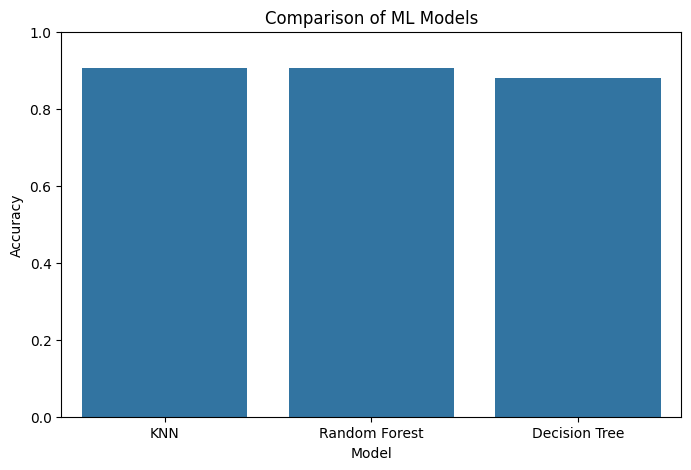

In [12]:
results_df = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Accuracy"]
).sort_values(by="Accuracy", ascending=False)

display(results_df)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Comparison of ML Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

In [13]:
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]

if best_model_name == "KNN":
    final_predictions = best_model.predict(X_test_scaled)
else:
    final_predictions = best_model.predict(X_test)

print("Best model:", best_model_name)
print(f"Accuracy: {accuracy_score(y_test, final_predictions):.2%}")

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

Best model: KNN
Accuracy: 90.48%

Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.71      0.83        14
           2       0.88      1.00      0.93        14
           3       0.88      1.00      0.93        14

    accuracy                           0.90        42
   macro avg       0.92      0.90      0.90        42
weighted avg       0.92      0.90      0.90        42



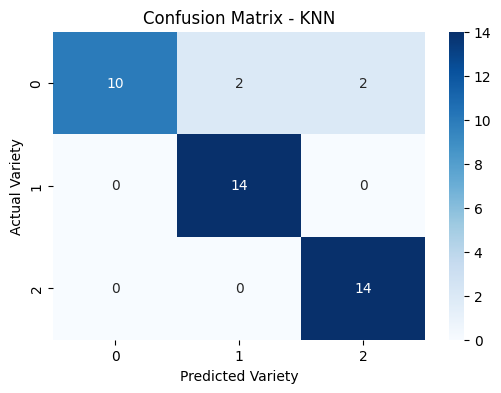

In [14]:
cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Variety")
plt.ylabel("Actual Variety")
plt.show()

In [15]:
sample_seed = pd.DataFrame(
    [[15.2, 14.1, 0.88, 5.5, 3.2, 2.1, 5.0]],
    columns=X.columns
)

if best_model_name == "KNN":
    sample_scaled = scaler.transform(sample_seed)
    predicted_variety = best_model.predict(sample_scaled)[0]
else:
    predicted_variety = best_model.predict(sample_seed)[0]

print("Predicted wheat seed variety:", predicted_variety)

Predicted wheat seed variety: 1


In [16]:
import joblib

joblib.dump(best_model, "wheat_seed_model.pkl")
joblib.dump(scaler, "wheat_seed_scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


## Conclusion

In this project, I developed a Machine Learning classification system
to identify wheat seed varieties using their physical characteristics.

I explored the dataset, visualized feature distributions, cleaned the data,
and trained K-Nearest Neighbors, Decision Tree, and Random Forest models.

I compared the models using accuracy and classification metrics and
evaluated the selected model using a confusion matrix.

This project demonstrates how supervised Machine Learning can be used
for seed variety classification.